# Task 61: Bias-Mitigation Strategy Comparison

Compare baseline logistic regression, group/outcome reweighting, and dropping the explicit sensitive feature using the same split, with both classification performance and group-fairness metrics.

Training group x outcome counts:


target,0,1
sex group,,
0,21,56
1,89,75


Reweight range: 0.747 1.674 mean: 1.0
Performance and fairness on same held-out split:


,accuracy,precision,recall,f1,disparate impact,DP gap,TPR gap,FPR gap
Strategy,,,,,,,,
Baseline,0.852,0.833,0.909,0.870,0.711,0.213,0.066,0.24
Reweighted,0.803,0.784,0.879,0.829,0.835,0.113,0.129,0.32
Sensitive field removed,0.820,0.806,0.879,0.841,0.800,0.137,0.129,0.28


Baseline group rates: {0: {'selection': 0.7368421052631579, 'TPR': np.float64(0.875), 'FPR': np.float64(0.0)}, 1: {'selection': 0.5238095238095238, 'TPR': np.float64(0.9411764705882353), 'FPR': np.float64(0.24)}}
Reweighted group rates: {0: {'selection': 0.6842105263157895, 'TPR': np.float64(0.8125), 'FPR': np.float64(0.0)}, 1: {'selection': 0.5714285714285714, 'TPR': np.float64(0.9411764705882353), 'FPR': np.float64(0.32)}}
Sensitive field removed group rates: {0: {'selection': 0.6842105263157895, 'TPR': np.float64(0.8125), 'FPR': np.float64(0.0)}, 1: {'selection': 0.5476190476190477, 'TPR': np.float64(0.9411764705882353), 'FPR': np.float64(0.28)}}


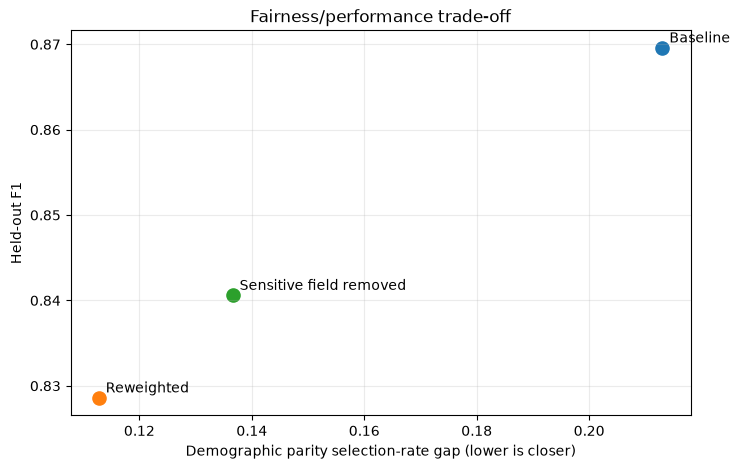

Compare fairness metrics jointly: reweighting changes the training objective; dropping sex may leave correlated proxies. Results are specific to this split and binary group field, and do not establish legal or clinical fairness.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

paths=[Path('heart.csv'),Path('Task_61_Bias_Mitigation_Strategies/heart.csv'),Path('Heart_Disease_Tasks/Task_61_Bias_Mitigation_Strategies/heart.csv')]
data=pd.read_csv(next(p for p in paths if p.is_file())).drop_duplicates().reset_index(drop=True)
features=[c for c in ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal'] if c in data]
X,y,group=data[features].to_numpy(float),data.target.to_numpy(int),data.sex.to_numpy(int)

def stratified_split_indices(labels,fraction,seed):
    rng=np.random.default_rng(seed);a=[];b=[]
    for label in np.unique(labels):
        ids=np.flatnonzero(labels==label);rng.shuffle(ids);cut=round(fraction*len(ids));a.extend(ids[:cut]);b.extend(ids[cut:])
    rng.shuffle(a);rng.shuffle(b);return np.array(a),np.array(b)
train_idx,test_idx=stratified_split_indices(y,.8,61)
X_train,X_test,y_train,y_test=X[train_idx],X[test_idx],y[train_idx],y[test_idx];group_train,group_test=group[train_idx],group[test_idx]
mean,scale=X_train.mean(0),X_train.std(0);scale[scale==0]=1
X_train,X_test=(X_train-mean)/scale,(X_test-mean)/scale
class ManualLogistic:
    def fit(self,x,y,sample_weight=None):
        weights=np.ones(len(y)) if sample_weight is None else np.asarray(sample_weight,dtype=float)
        weights=weights/weights.sum();self.w=np.zeros(x.shape[1]);self.b=0.
        for _ in range(1400):
            probability=1/(1+np.exp(-np.clip(x@self.w+self.b,-35,35)));error=probability-y;weighted=weights*error
            self.w-=.06*(x.T@weighted+.02*self.w);self.b-=.06*weighted.sum()
        return self
    def predict(self,x,threshold=.5):return (1/(1+np.exp(-np.clip(x@self.w+self.b,-35,35)))>=threshold).astype(int)

def reweigh(y,group_values):
    weights=np.zeros(len(y),dtype=float)
    for g in np.unique(group_values):
        for label in np.unique(y):
            mask=(group_values==g)&(y==label)
            if mask.any():weights[mask]=np.mean(group_values==g)*np.mean(y==label)/np.mean(mask)
    return weights/weights.mean()

def group_metrics(actual,predicted,group_values):
    result={}
    for label in np.unique(group_values):
        mask=group_values==label;a=actual[mask];p=predicted[mask]
        tp=np.sum((a==1)&(p==1));fp=np.sum((a==0)&(p==1));tn=np.sum((a==0)&(p==0));fn=np.sum((a==1)&(p==0))
        result[int(label)]={'selection':float(p.mean()),'TPR':tp/(tp+fn) if tp+fn else np.nan,'FPR':fp/(fp+tn) if fp+tn else np.nan}
    return result

def summarize(actual,predicted,groups):
    tp=np.sum((actual==1)&(predicted==1));tn=np.sum((actual==0)&(predicted==0));fp=np.sum((actual==0)&(predicted==1));fn=np.sum((actual==1)&(predicted==0))
    precision=tp/(tp+fp) if tp+fp else 0.;recall=tp/(tp+fn) if tp+fn else 0.;by_group=group_metrics(actual,predicted,groups)
    rates=[r['selection'] for r in by_group.values()];di=min(rates)/max(rates) if max(rates)>0 else np.nan
    tpr=[r['TPR'] for r in by_group.values() if np.isfinite(r['TPR'])];fpr=[r['FPR'] for r in by_group.values() if np.isfinite(r['FPR'])]
    return {'accuracy':(tp+tn)/len(actual),'precision':precision,'recall':recall,'f1':2*precision*recall/(precision+recall) if precision+recall else 0.,'disparate impact':di,'DP gap':max(rates)-min(rates),'TPR gap':max(tpr)-min(tpr),'FPR gap':max(fpr)-min(fpr)},by_group

baseline=ManualLogistic().fit(X_train,y_train)
weights=reweigh(y_train,group_train)
reweighted=ManualLogistic().fit(X_train,y_train,weights)
sex_index=features.index('sex');keep=[i for i in range(len(features)) if i!=sex_index]
dropped=ManualLogistic().fit(X_train[:,keep],y_train)
models={'Baseline':baseline.predict(X_test),'Reweighted':reweighted.predict(X_test),'Sensitive field removed':dropped.predict(X_test[:,keep])}
summary=[];group_summaries={}
for name,predicted in models.items():
    row,by_group=summarize(y_test,predicted,group_test);summary.append({'Strategy':name,**row});group_summaries[name]=by_group
results=pd.DataFrame(summary).set_index('Strategy')
print('Training group x outcome counts:');display(pd.crosstab(group_train,y_train,rownames=['sex group'],colnames=['target']))
print('Reweight range:',round(weights.min(),3),round(weights.max(),3),'mean:',round(weights.mean(),3))
print('Performance and fairness on same held-out split:');display(results.round(3))
for name,values in group_summaries.items():print(name,'group rates:',values)

fig,ax=plt.subplots(figsize=(8,5))
for strategy,row in results.iterrows():ax.scatter(row['DP gap'],row['f1'],s=90,label=strategy);ax.annotate(strategy,(row['DP gap'],row['f1']),xytext=(5,4),textcoords='offset points')
ax.set_xlabel('Demographic parity selection-rate gap (lower is closer)');ax.set_ylabel('Held-out F1');ax.set_title('Fairness/performance trade-off');ax.grid(alpha=.25);plt.show()
print('Compare fairness metrics jointly: reweighting changes the training objective; dropping sex may leave correlated proxies. Results are specific to this split and binary group field, and do not establish legal or clinical fairness.')